In [18]:
import os
import json
import base64
import gradio as gr
from dotenv import load_dotenv
from PIL import Image
from io import BytesIO
from openai import OpenAI
import requests
import sqlite3


In [23]:
load_dotenv(override=True)
open_route_key=os.getenv("OPENROUTER_API_KEY")
if open_route_key:
    print(f"OpenAI API Key exists and begins {open_route_key[:8]}")
else:
    print("OpenAI API Key not set")

MODEL = "gpt-4.1-mini"
DB = "prices.db"

OpenAI API Key exists and begins sk-or-v1


In [3]:
openrouter_url = "https://openrouter.ai/api/v1"
client = OpenAI(api_key=open_route_key,base_url=openrouter_url)

In [4]:
system_message = """
You are a helpful assistant for an Airline called FlightAI.
Give short, courteous answers, no more than 1 sentence.
Always be accurate. If you don't know the answer, say so.
"""

In [12]:
import os
from urllib.parse import quote

load_dotenv(override=True)
POLLINATIONS_API_KEY=os.getenv("POLLINATIONS_API_KEY")

print("API key loaded:", bool(os.getenv("POLLINATIONS_API_KEY")))

API key loaded: True


In [13]:

def artist(city):


    if not POLLINATIONS_API_KEY:
        raise ValueError("Pollinations API key is missing!")

    prompt = (
        f"An image representing a vacation in {city}, "
        f"showing famous tourist spots, landmarks, "
        f"local culture and everything unique about {city}, "
        f"in a vibrant pop-art style, colorful illustration, "
        f"high detail, beautiful composition."
    )

    url = f"https://gen.pollinations.ai/image/{quote(prompt)}"

    headers = {
        "Authorization": f"Bearer {POLLINATIONS_API_KEY}"
    }

    params = {
        "model": "black-forest-labs/flux.1-schnell",
        "width": 1024,
        "height": 1024
    }

    response = requests.get(
        url,
        headers=headers,
        params=params,
        timeout=180
    )

    if response.status_code != 200:
        raise RuntimeError(
            f"Image generation failed: "
            f"{response.status_code} - {response.text[:1000]}"
        )

    image = Image.open(
        BytesIO(response.content)
    ).convert("RGB")

    return image


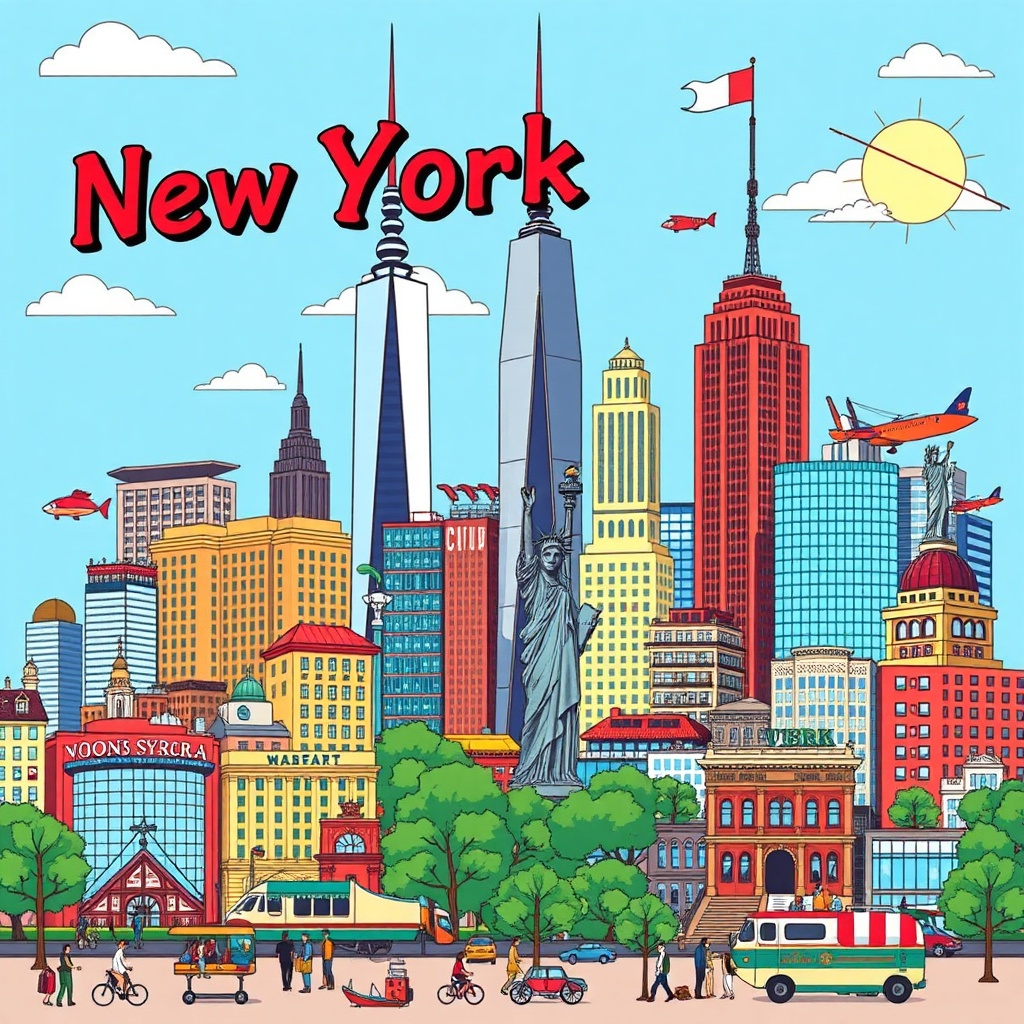

In [15]:
image = artist("New York City")
display(image)

In [26]:
import sqlite3
import os

DB = "prices.db"

with sqlite3.connect(DB) as conn:
    cursor = conn.cursor()

    cursor.execute("""
        CREATE TABLE IF NOT EXISTS prices (
            city TEXT PRIMARY KEY,
            price REAL
        )
    """)

    cursor.executemany("""
        INSERT OR IGNORE INTO prices (city, price)
        VALUES (?, ?)
    """, [
        ("paris", 500),
        ("london", 600),
        ("tokyo", 450),
        ("new york", 800)
    ])

print("Database and prices table initialized successfully!")
print("Database location:", os.path.abspath(DB)) 

Database and prices table initialized successfully!
Database location: c:\Users\hp\LLM_ENGINEERING\agents\week2\community-contributions\jamil\prices.db


In [27]:
def get_ticket_price(city):
    print(f"DATABASE TOOL CALLED: Getting price for {city}", flush=True)
    with sqlite3.connect(DB) as conn: 
        cursor = conn.cursor()
        cursor.execute('SELECT price FROM prices WHERE city = ?', (city.lower(),))
        result = cursor.fetchone()
        return f"Ticket price to {city} is ${result[0]}" if result else "No price data available for this city"

In [28]:
get_ticket_price("Paris") 

DATABASE TOOL CALLED: Getting price for Paris


'Ticket price to Paris is $500.0'

In [29]:
price_function = {
    "name": "get_ticket_price",
    "description": "Get the price of a return ticket to the destination city.",
    "parameters": {
        "type": "object",
        "properties": {
            "destination_city": {
                "type": "string",
                "description": "The city that the customer wants to travel to",
            },
        },
        "required": ["destination_city"],
        "additionalProperties": False
    }
}
tools = [{"type": "function", "function": price_function}]
tools

[{'type': 'function',
  'function': {'name': 'get_ticket_price',
   'description': 'Get the price of a return ticket to the destination city.',
   'parameters': {'type': 'object',
    'properties': {'destination_city': {'type': 'string',
      'description': 'The city that the customer wants to travel to'}},
    'required': ['destination_city'],
    'additionalProperties': False}}}]

In [30]:
def chat(message,history):
    history = [{"role":h["role"],"content":h["content"]} for h in history]
    messages = [{"role": "system", "content": system_message}] + history + [{"role": "user", "content": message}]
    response = client.chat.completions.create(model=MODEL, messages=messages)
    return response.choices[0].message.content